# Lab: Relationships in Space and Time

Select **two distinct datasets that each contain both spatial and temporal information**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of Plotly Express figures for each question**, for a total of two research questions and four figures.

Together, each pair of figures must help answer where and when the pattern occurs. A map and a time-series plot are one useful combination; other combinations are welcome when you explain how they address both space and time.

## Learning goals

- Select and document datasets with usable location and time features.
- Ask focused questions that connect a measurement or event count to both space and time.
- Prepare dates, geographic identifiers, and summaries appropriately for the question.
- Create and compare two complementary interactive figures for each question.
- Check plotted values and ordering against the records.
- Support conclusions with evidence and explain the limitations of the data and displays.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.

## Select your two datasets

Each dataset needs:

- A documented publisher and feature definitions or data dictionary.
- A usable **time feature**, such as a timestamp, date, month, or year, with observations from multiple times.
- A usable **spatial feature**, such as coordinates, station locations, or named geographic areas with matching identifiers, covering multiple places or a moving object's locations.
- A quantitative measurement with known units, or event records that support a meaningful count.
- Enough usable observations to compare places and periods. A file with dates from one fixed location alone will not support a spatial comparison.

Use two distinct datasets, not two filters of the same file. Choose your own questions and records rather than reproducing a worked lecture example. The suggestions below are starting points, not required choices. You may select another documented source.

Choose manageable geographic and time ranges before downloading. A country or city name does not automatically provide coordinates; document any station lookup, geographic-code lookup, or boundary file you need. Save fixed copies in this notebook's `data` folder, preserve the original records, and use relative paths. Include supporting lookup files with your submission.

### Candidate datasets

| Candidate and source | Useful spatial and time information | Possible question and figure pair |
| --- | --- | --- |
| [USGS earthquake catalog](https://earthquake.usgs.gov/earthquakes/search/) and [CSV field definitions](https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php) | Event time, coordinates, magnitude, and depth. Limit the dates, geographic bounds, and magnitude range; download CSV. | Where did recorded earthquakes cluster during a selected period, and how did monthly counts change? Use a point or density map and a monthly count plot. |
| [NOAA daily weather observations](https://www.ncei.noaa.gov/cdo-web/search) and [GHCNd documentation](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily) | Station identifiers, dates, temperature or precipitation, and documented station locations. Select several stations and the same time span. | How did monthly precipitation differ among selected locations during a year? Use a station map of monthly summaries and a line plot or location-by-month heatmap. |
| [EPA daily air-quality data](https://www.epa.gov/outdoor-air-quality-data/download-daily-data) and [file documentation](https://aqs.epa.gov/aqsweb/airdata/download_files.html) | Monitor or county identifiers, dates, pollutant measurements or AQI. Use one pollutant and compatible units; obtain station coordinates if making a point map. | Where and when were PM2.5 concentrations highest among selected monitors? Use a map and a time-series plot grouped by monitor. |
| [NOAA Storm Events Database](https://www.ncei.noaa.gov/access/storm-events-database/) | Event dates, states/counties, event types, and locations when reported. Start with one event type, a few states, and a limited period. | How did reported hail-event counts vary across selected counties and months? Use a county choropleth and a county-by-month heatmap. County boundaries/codes are needed for the map. |

Adapt the question to the fields actually available. Counts of reported events or monitor observations can reflect reporting and sampling effort as well as the underlying phenomenon. Do not treat missing observations as zero events or average measurements with incompatible units.

## Choose two complementary figures per question

Choose **different chart types**, not two copies that differ only in color, title, filter, or static-versus-animated display. You may reuse a useful chart type with the second dataset. An animation counts as one figure, regardless of its number of frames. Animation is optional; a well-chosen static comparison can be easier to interpret.

| Figure | Plotly Express tools | What it can help you see |
| --- | --- | --- |
| Time-series line plot | `px.line()` | How a measurement changes over time; color or separate panels can distinguish locations. Sort dates within each series before connecting points. |
| Point or bubble map | `px.scatter_geo()` or `px.scatter_map()` | Where observations occur; color and size can show quantitative values. Time can appear in hover information, filters, or animation. |
| Choropleth | `px.choropleth()` | How an area-level summary varies geographically, optionally animated by period. Match country/state codes or supply matching GeoJSON boundaries. |
| Bubble scatterplot | `px.scatter()` | How two quantitative features relate; geographic groups and time can be represented by color and animation. Explain how location is represented if this replaces a map. |
| Geographic path — an additional option | `px.line_geo()` or `px.line_map()` | A recorded route or moving object's sequence of positions. Sort within each tracked object; do not connect unrelated events into a path. |
| Spatial density map — an additional option | `px.density_map()` | Where many nearby point observations concentrate. The smoothing radius affects the appearance; this is not automatically a rate or a map of risk. |
| Location-by-time heatmap — an additional option | `px.imshow()` | Rows represent locations, columns represent ordered periods, and color represents a count or measurement. Summarize to one value per location-period first. |

Use the [Plotly map guide](https://plotly.com/python/map-configuration/), [heatmap guide](https://plotly.com/python/heatmaps/), and [animation guide](https://plotly.com/python/animations/) for examples and parameters. Tile maps need access to background tiles; geographic maps may also need internet access for boundary outlines.

### Starting patterns for additional chart types

These are **adaptation examples**, not code to run unchanged. Replace the DataFrame and feature names with yours. They do not add requirements to your four figures.

**Path of a tracked object:** only use this when consecutive rows describe the same object's movement.

```python
track_df.sort_values(['object_id', 'date'], inplace=True)
fig = px.line_geo(track_df, lat='latitude', lon='longitude',
                  color='object_id', hover_data=['date'],
                  title='Recorded paths')
fig.update_layout(height=500)
fig.show()
```

**Density of point observations:** omit `z` to give every row equal weight. Document any deliberate weighting.

```python
fig = px.density_map(events_df, lat='latitude', lon='longitude',
                     radius=15, map_style='open-street-map',
                     title='Concentration of recorded events')
fig.update_layout(height=500)
fig.show()
```

**Location-by-month heatmap:** this example uses a mean measurement. Use a sum or count only when that statistic answers your question. Missing cells remain missing unless you can establish that a zero is appropriate.

```python
observations_df['month'] = observations_df['date'].dt.to_period('M').astype(str)
monthly_df = observations_df.groupby(['location', 'month'])['value'].mean().reset_index()
grid = monthly_df.pivot(index='location', columns='month', values='value')
grid = grid.reindex(sorted(grid.columns), axis=1)
fig = px.imshow(grid, aspect='auto',
                labels={'x':'Month', 'y':'Location', 'color':'Mean value'},
                title='Mean measurement by location and month')
fig.update_layout(height=500)
fig.show()
```

### Make the comparison interpretable

Use descriptive titles, labels with units, and informative hover fields. Start with `fig.update_layout(height=500)` and adjust only if needed. Keep scales consistent when comparing frames or panels. Use a manageable number of time periods—monthly, quarterly, or yearly frames often work better than hundreds of daily frames. Explain any aggregation and retain the original dates.

For maps, confirm that geographic codes match the boundaries and that points appear in plausible places. Numeric identifiers are not quantitative measurements. A colored area or large marker does not necessarily mean greater risk: consider population, area, observation effort, and what the encoded value actually measures.

In [ ]:
# Import Pandas and Plotly Express.

## Investigation 1: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer:

Research Question: How did the number of recorded red tide samples vary across Florida sampling locations from June through November 2018?

Prediction: I predict that the number of recorded samples will vary between locations and months, with some coastal areas having more samples during certain periods than others.

Looking at both location and time helps identify where sampling activity was concentrated and when it increased or decreased. This provides a more complete picture than examining locations or dates separately.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer:

**Dataset Title:** Florida Red Tide Samples, June–November 2018

**Publisher:** To be confirmed from the original dataset source.

**Direct Source URL:** To be added from the original source.

**Data Dictionary:** To be confirmed from the dataset documentation.

**Access Date:** September 30, 2026 (if this is when the dataset was obtained).

**Saved File:** florida_red_tide_samples_june_november_2018.csv

**Lookup or Boundary Files:** None identified at this stage.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer:

Each row represents an individual red tide sampling observation recorded at a particular Florida location and date. The dataset covers June through November 2018. The observations were collected through environmental sampling and monitoring activities. The exact sampling locations and collection methods should be confirmed using the dataset documentation.

In [5]:
import pandas as pd

red_tide_df = pd.read_csv(
    "data/florida_red_tide_samples_june_november_2018.csv"
)

print("Dataset loaded successfully.")
print("Columns:", red_tide_df.columns.tolist())

red_tide_df["sample_date"] = pd.to_datetime(
    red_tide_df["sample_date"]
)

Dataset loaded successfully.
Columns: ['sample_date', 'location', 'latitude', 'longitude', 'sample_depth_m', 'karenia_brevis_cells_per_liter', 'abundance_category']


In [6]:
print("First five rows:")
display(red_tide_df.head())

print("Last five rows:")
display(red_tide_df.tail())

print("Dataset shape:")
print(red_tide_df.shape)

First five rows:


,sample_date,location,latitude,longitude,sample_depth_m,karenia_brevis_cells_per_liter,abundance_category
0,2018-06-01,Red Reef Park Beach,26.36043,-80.06847,0.5,0.0,Not present/background
1,2018-06-01,Gumbo Limbo Nature Center (Lake Wyman),26.36751,-80.07118,0.5,0.0,Not present/background
2,2018-06-01,Bay Dock (Sarasota Bay),27.33160,-82.57790,0.5,5000.0,Very low
3,2018-06-01,New Pass Dock (Sarasota Bay),27.33375,-82.57938,0.5,1000.0,Not present/background
4,2018-06-01,Dixie Highway Bridge; E of (Indian River),27.85566,-80.49085,1.3,0.0,Not present/background


Last five rows:


,sample_date,location,latitude,longitude,sample_depth_m,karenia_brevis_cells_per_liter,abundance_category
7287,2018-11-29,Brooks Bridge; W of (Santa Rosa Sound),30.400800,-86.600800,0.1,0.0,Not present/background
7288,2018-11-30,Gasparilla Island; 10 mi W of,26.722583,-82.366933,0.5,20667.0,Low
7289,2018-11-30,Gasparilla Island; 13 mi W of,26.760700,-82.475550,0.5,391020.0,Medium
7290,2018-11-30,Bay Dock (Sarasota Bay),27.331600,-82.577900,0.5,534000.0,Medium
7291,2018-11-30,New Pass Dock (Sarasota Bay),27.333750,-82.579380,0.5,274000.0,Medium


Dataset shape:
(7292, 7)


In [4]:
print("Dataset information:")
red_tide_df.info()

print("\nMissing values by column:")
display(red_tide_df.isna().sum())

red_tide_df["sample_date"] = pd.to_datetime(
    red_tide_df["sample_date"]
)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7292 entries, 0 to 7291
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   sample_date                     7292 non-null   str    
 1   location                        7292 non-null   str    
 2   latitude                        7292 non-null   float64
 3   longitude                       7292 non-null   float64
 4   sample_depth_m                  7259 non-null   float64
 5   karenia_brevis_cells_per_liter  7292 non-null   float64
 6   abundance_category              7292 non-null   str    
dtypes: float64(4), str(3)
memory usage: 398.9 KB

Missing values by column:


sample_date                        0
location                           0
latitude                           0
longitude                          0
sample_depth_m                    33
karenia_brevis_cells_per_liter     0
abundance_category                 0
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| | | | | |

Use quantitative, categorical, or temporal for feature type.

Your answer:

Each row represents one water sampling observation at a specific Florida location on a particular date. The dataset contains 7,292 observations from June 1 through November 30, 2018. It includes sampling locations, latitude and longitude, sampling depth, Karenia brevis cell concentrations per liter, and abundance categories. These measurements allow red tide conditions to be compared across different locations and dates. The dataset has 33 missing sampling-depth values, but all other columns are complete.

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer:

I will use the Florida red tide sampling dataset containing 7,292 observations from June through November 2018. I will examine how Karenia brevis cell concentrations vary across Florida sampling locations and over time. The main features are sample_date, location, latitude, longitude, karenia_brevis_cells_per_liter, and abundance_category. I will group observations by month and sampling location to compare changes over time and across geographic areas. I will calculate sample counts and average cell concentrations for each group. The 33 missing sampling-depth values will be retained because sampling depth is not required for these comparisons.

In [7]:
# Prepare the analysis data
original_count = len(red_tide_df)

analysis_df = red_tide_df.copy()

# Convert sample dates to datetime
analysis_df["sample_date"] = pd.to_datetime(
    analysis_df["sample_date"]
)

# Remove rows missing required analysis fields
required_columns = [
    "sample_date",
    "location",
    "latitude",
    "longitude",
    "karenia_brevis_cells_per_liter"
]

analysis_df = analysis_df.dropna(subset=required_columns)

# Create monthly time periods
analysis_df["month"] = analysis_df["sample_date"].dt.to_period("M").astype(str)

# Sort by location and date
analysis_df = analysis_df.sort_values(
    ["location", "sample_date"]
)

# Summarize observations by month and location
red_tide_summary = (
    analysis_df.groupby(["month", "location"], as_index=False)
    .agg(
        sample_count=("karenia_brevis_cells_per_liter", "size"),
        mean_cells_per_liter=("karenia_brevis_cells_per_liter", "mean"),
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean")
    )
    .sort_values(["location", "month"])
)

print("Original records:", original_count)
print("Retained records:", len(analysis_df))
print("Records removed:", original_count - len(analysis_df))
print("Monthly location groups:", len(red_tide_summary))

print("\nMonthly summary:")
display(red_tide_summary.head(10))

Original records: 7292
Retained records: 7292
Records removed: 0
Monthly location groups: 3774

Monthly summary:


,month,location,sample_count,mean_cells_per_liter,latitude,longitude
1616,2018-09,100th Avenue N; canal W of,1,0.0,26.262468,-81.819563
520,2018-07,122nd Street Ocean; SW of (Hawk Channel),1,0.0,24.728650,-81.026000
2282,2018-10,123 Avenue Boat Launch (Boca Ciega Bay),1,13645800.0,27.778889,-82.778452
2283,2018-10,123rd Avenue Boat Launch (Boca Ciega Bay),1,4620420.0,27.778900,-82.778500
2284,2018-10,123rd Avenue Boat Ramp (Boca Ceiga Bay),1,4302461.0,27.778950,-82.778450
3159,2018-11,123rd Avenue Boat Ramp (Boca Ciega Bay),2,3227910.0,27.778977,-82.778433
2285,2018-10,123rd Avenue; E of (Boca Ciega Bay),1,3168060.0,27.778887,-82.778480
2286,2018-10,123rd Avenue; W of,1,9919689.0,27.776880,-82.781817
953,2018-08,15th Avenue; boat ramp E of (Clearwater Harbor),1,0.0,27.897201,-82.843472
1617,2018-09,15th Avenue; boat ramp E of (ICW),1,667.0,27.897200,-82.843435


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer:

No records were removed from the original dataset. All 7,292 observations were retained because the required dates, locations, coordinates, and cell concentration measurements were complete. The 33 missing sampling-depth values were not relevant to this analysis. After aggregation, each row in the monthly summary represents one sampling location during one month, including its sample count, average Karenia brevis concentration, and geographic coordinates.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer:

I will use an animated geographic scatter map and a line chart. The map will display Florida sampling locations using latitude and longitude, with monthly animation frames from June through November 2018. Marker color will represent average Karenia brevis cells per liter. The line chart will display months on the horizontal axis and average cells per liter on the vertical axis. The map will help identify geographic patterns, while the line chart will make changes over time easier to compare.

In [11]:
%pip install --upgrade nbformat ipython ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:

import plotly.express as px

# Figure 1: Animated geographic scatter plot
fig1 = px.scatter(
    red_tide_summary,
    x="longitude",
    y="latitude",
    color="mean_cells_per_liter",
    animation_frame="month",
    hover_name="location",
    hover_data={
        "sample_count": True,
        "mean_cells_per_liter": ":,.0f",
        "latitude": ":.4f",
        "longitude": ":.4f"
    },
    color_continuous_scale="YlOrRd",
    range_color=[
        0,
        red_tide_summary["mean_cells_per_liter"].max()
    ],
    range_x=[-88, -79],
    range_y=[24, 31],
    title="Florida Red Tide Concentrations by Month (June-November 2018)",
    labels={
        "longitude": "Longitude",
        "latitude": "Latitude",
        "mean_cells_per_liter": "Average cells/L",
        "sample_count": "Number of samples"
    }
)

fig1.update_layout(height=500)

# Save and open Figure 1 in your browser
fig1.write_html(
    "florida_red_tide_figure1.html",
    include_plotlyjs=True,
    full_html=True,
    auto_open=True
)

print("Figure 1 created successfully.")


Figure 1 created successfully.


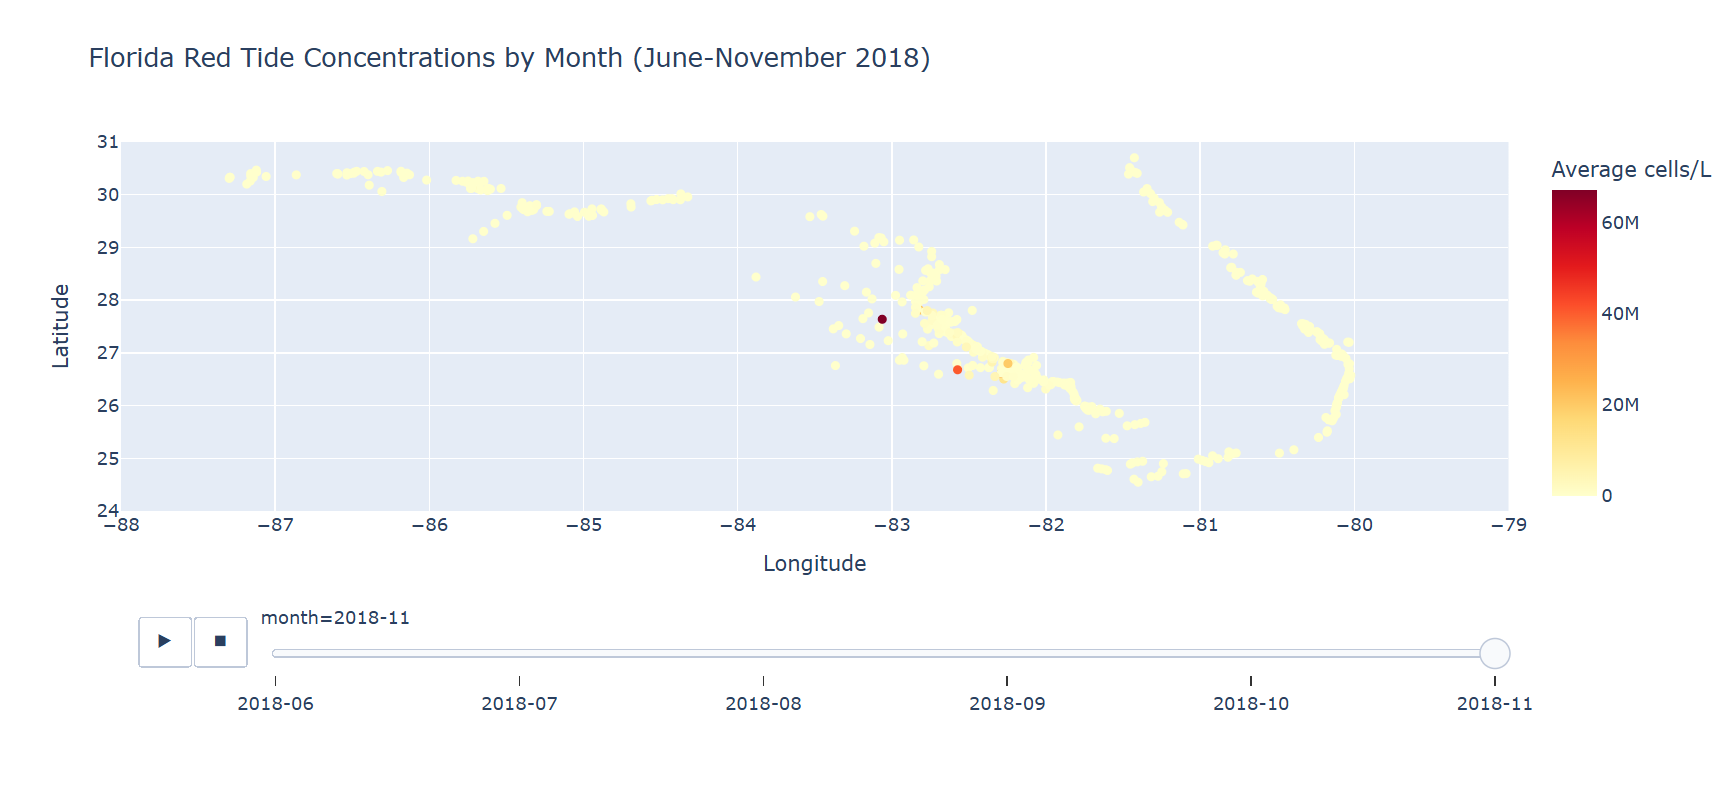

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer:

Figure 1 shows how Florida red tide concentrations varied by location and month from June through November 2018. The geographic scatter plot uses longitude and latitude to identify sampling locations, while color represents the average concentration of Karenia brevis cells per liter. In November 2018, most sampling locations showed relatively low concentrations, but several locations along Florida's Gulf Coast had noticeably higher concentrations. The chart demonstrates that red tide conditions were not uniform across Florida and allows changes in geographic distribution to be compared over time.

In [17]:

import plotly.express as px

# Calculate monthly average red tide concentrations
monthly_trends = (
    red_tide_df.groupby("month", as_index=False)
    .agg(
        mean_cells_per_liter=(
            "karenia_brevis_cells_per_liter", "mean"
        ),
        sample_count=(
            "karenia_brevis_cells_per_liter", "size"
        )
    )
    .sort_values("month")
)

# Figure 2: Monthly red tide concentration trends
fig2 = px.line(
    monthly_trends,
    x="month",
    y="mean_cells_per_liter",
    markers=True,
    hover_data={
        "sample_count": True,
        "mean_cells_per_liter": ":,.0f"
    },
    title="Average Florida Red Tide Concentrations by Month (June-November 2018)",
    labels={
        "month": "Month",
        "mean_cells_per_liter": "Average Karenia brevis cells/L",
        "sample_count": "Number of samples"
    }
)

fig2.update_layout(
    height=500,
    xaxis=dict(type="category"),
    yaxis=dict(rangemode="tozero")
)

# Display monthly summary table
print("Monthly Red Tide Summary:")
display(monthly_trends)

# Save and open Figure 2 in your browser
fig2.write_html(
    "florida_red_tide_figure2.html",
    include_plotlyjs=True,
    full_html=True,
    auto_open=True
)

print("Figure 2 created successfully.")


Monthly Red Tide Summary:


,month,mean_cells_per_liter,sample_count
0,2018-06,1.186693e+05,991
1,2018-07,6.531038e+05,865
2,2018-08,1.254406e+06,1236
3,2018-09,4.488527e+05,1196
4,2018-10,2.116852e+05,1855
5,2018-11,7.207665e+05,1149


Figure 2 created successfully.


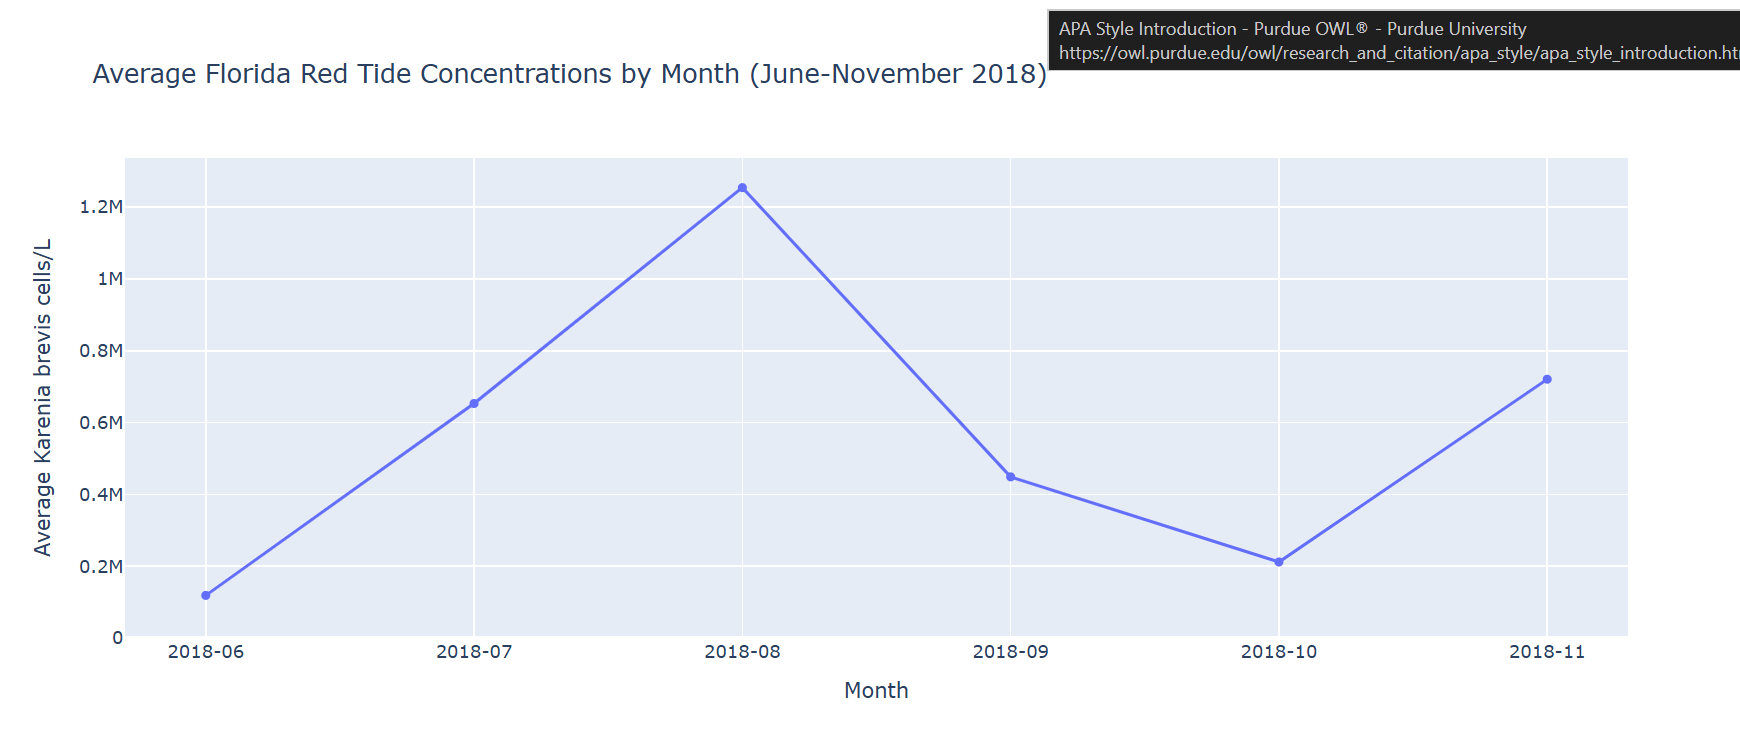

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer:

Figure 2 shows how average Karenia brevis concentrations changed across Florida from June through November 2018. Concentrations increased from approximately 120,000 cells per liter in June to a peak of approximately 1.25 million cells per liter in August. They then decreased to approximately 210,000 cells per liter in October before rising again to approximately 720,000 cells per liter in November. Unlike Figure 1, which shows where concentrations occurred geographically, Figure 2 makes the monthly changes easier to compare. Together, the figures show that red tide concentrations varied by both location and time. However, the statewide monthly averages may be influenced by differences in sampling locations and sample counts.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [18]:

# Step 4: Verify plotted values and data consistency

# Check August and October monthly averages
check_months = monthly_trends[
    monthly_trends["month"].isin(["2018-08", "2018-10"])
]

print("Values to compare with Figure 2:")
display(check_months)

# Verify chronological order
print("\nMonths in chronological order:")
print(monthly_trends["month"].tolist())

# Check geographic coordinates
print("\nGeographic coordinate ranges:")
print("Latitude:", red_tide_summary["latitude"].min(),
      "to", red_tide_summary["latitude"].max())
print("Longitude:", red_tide_summary["longitude"].min(),
      "to", red_tide_summary["longitude"].max())

# Identify the highest monthly concentration
print("\nHighest monthly average:")
display(
    monthly_trends.nlargest(1, "mean_cells_per_liter")
)

# Check a high-concentration location in Figure 1
print("\nHighest location-month average:")
display(
    red_tide_summary.nlargest(1, "mean_cells_per_liter")
)


Values to compare with Figure 2:


,month,mean_cells_per_liter,sample_count
2,2018-08,1.254406e+06,1236
4,2018-10,2.116852e+05,1855



Months in chronological order:
['2018-06', '2018-07', '2018-08', '2018-09', '2018-10', '2018-11']

Geographic coordinate ranges:
Latitude: 24.455 to 30.7012
Longitude: -87.325914 to -79.9488

Highest monthly average:


,month,mean_cells_per_liter,sample_count
2,2018-08,1.254406e+06,1236



Highest location-month average:


,month,location,sample_count,mean_cells_per_liter,latitude,longitude
3356,2018-11,Egmont Key; 19 mi W of,1,67254526.0,27.6372,-83.0622


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer:

I checked the August and October 2018 red tide concentrations against the calculated monthly summary. August averaged approximately 1,254,406 Karenia brevis cells per liter from 1,236 samples, while October averaged approximately 211,685 cells per liter from 1,855 samples. Both values agreed with Figure 2. I confirmed that the months were ordered chronologically from June through November 2018 and that the geographic coordinates matched the Florida sampling region. One unusual observation was at Egmont Key, 19 miles west, where the November average reached 67,254,526 cells per liter. However, this location-month average was based on only one sample, so it should be interpreted cautiously. No errors requiring correction were identified.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer:

My research question was how Florida red tide concentrations varied by location and month from June through November 2018. The results show that concentrations changed significantly across both time and geographic locations. Figure 1 showed that red tide concentrations were unevenly distributed around Florida, with some Gulf Coast locations experiencing much higher concentrations than others. For example, a November sample collected 19 miles west of Egmont Key measured 67,254,526 Karenia brevis cells per liter. Figure 2 showed that the statewide monthly average increased to approximately 1,254,406 cells per liter in August before declining to approximately 211,685 cells per liter in October. Concentrations increased again in November. These results support my prediction that red tide concentrations would vary across Florida and change over time, with some coastal areas experiencing more severe concentrations than others.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:

Two limitations of this analysis are differences in sampling coverage and the influence of extreme measurements. The number and locations of samples varied between months, meaning the statewide averages may not represent every coastal area equally. Additionally, unusually high concentrations can influence the averages, especially when a location has only one sample, such as the November observation west of Egmont Key.

Figure 1 is useful for identifying geographic differences and locating areas with high concentrations, but it is harder to compare overall monthly trends because the points change between animation frames. Figure 2 makes changes over time easier to identify, including the August peak and October decline, but it combines observations from different locations into statewide averages and hides local differences. Using both figures provides a more complete understanding of how red tide concentrations varied across Florida during the study period.

## Investigation 2: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer:

My research question is: How did Karenia brevis concentrations change across Florida coastal sampling locations between June and November 2018, and which months experienced the highest concentrations?

I predict that concentrations will be higher during the late summer and fall months, particularly along Florida's Gulf Coast. Considering both location and time is important because red tide conditions can vary between coastal areas and change significantly from month to month. Analyzing both factors helps identify when and where the highest concentrations occurred.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer:

The dataset is NOAA Storm Events Database: 2024 Storm Events Details, published by the National Oceanic and Atmospheric Administration (NOAA) through the National Centers for Environmental Information (NCEI).

Direct source URL: https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/StormEvents_details-ftp_v1.0_d2024_c20260728.csv.gz

Data dictionary: https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/Storm-Data-Bulk-csv-Format.pdf

Access date: October 17, 2026.

Saved file: data/StormEvents_details-ftp_v1.0_d2024_c20260728.csv

No additional lookup tables or geographic boundary files are being used. The dataset already includes state names and geographic coordinates.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer:

Each row in the original dataset represents one reported storm event recorded by NOAA during 2024. For this investigation, I filtered the dataset to include only tornado events. Each remaining row represents a tornado event, including its date, location, state, and other reported characteristics.

The dataset covers tornadoes reported across the United States from January 1 through December 31, 2024. NOAA compiles these records using reports and assessments from National Weather Service offices and other storm information sources. These observations allow me to compare tornado activity across different states and months to identify geographic and seasonal patterns.

In [20]:
original_record_count = len(tornado_df)
print("Original storm event records:", original_record_count)

Original storm event records: 2137


In [21]:
print("First five tornado records:")
display(tornado_df.head())

print("Last five tornado records:")
display(tornado_df.tail())

print("Dataset shape:")
print(tornado_df.shape)

First five tornado records:


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE
19,202411,5,1101,202411,5,1102,196653,1216653,IOWA,19,...,4.10,ESE,BELKNAP,40.8030,-92.3482,40.8062,-92.3437,A brief tornado occurred with a shower in Davi...,A brief tornado occurred south of Floris from ...,CSV
107,202402,27,1932,202402,27,1935,188190,1155977,ILLINOIS,17,...,2.11,S,INVERNESS,42.0572,-88.1184,42.0898,-88.0937,"Following summer-like, record warmth, severe t...",This tornado touched down in the area near Del...,CSV
108,202402,27,1934,202402,27,1937,188190,1155978,ILLINOIS,17,...,1.69,SSW,INVERNESS,42.0722,-88.1485,42.0994,-88.1177,"Following summer-like, record warmth, severe t...",This tornado formed near Studio Drive in South...,CSV
113,202402,27,1815,202402,27,1816,188190,1155954,ILLINOIS,17,...,1.20,W,PAW PAW AIRPORT,41.7168,-89.0537,41.7173,-89.0529,"Following summer-like, record warmth, severe t...","A brief tornado, which was sighted by storm ch...",CSV
120,202402,27,1917,202402,27,1919,188190,1155975,ILLINOIS,17,...,0.31,SE,GENEVA,41.8827,-88.3482,41.8866,-88.3262,"Following summer-like, record warmth, severe t...",This tornado touched down along Keslinger Road...,CSV


Last five tornado records:


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE
69748,202406,26,1826,202406,26,1827,193907,1198110,PENNSYLVANIA,42,...,2.0,E,POPOFFS CORNERS,40.4269,-80.3060,40.4260,-80.2970,A well-organized upper shortwave trough crossi...,A National Weather Service survey concluded th...,CSV
69750,202406,5,2337,202406,5,2340,192638,1189052,OHIO,39,...,0.0,E,FRAYSZEBURG,40.1191,-82.1367,40.1194,-82.1131,Placeholder.,A strong tornado occurred during the overnight...,CSV
69752,202406,26,1906,202406,26,1920,193907,1198138,PENNSYLVANIA,42,...,1.0,NW,GREENWALD,40.3955,-79.6606,40.3768,-79.4560,A well-organized upper shortwave trough crossi...,"On the evening of Wednesday, June 26th a small...",CSV
69757,202406,26,1927,202406,26,1929,193907,1198121,PENNSYLVANIA,42,...,2.0,S,KIRBY,39.7769,-80.1302,39.7768,-80.1260,A well-organized upper shortwave trough crossi...,NWS Pittsburgh confirmed that an EF-0 tornado ...,CSV
69761,202406,26,1900,202406,26,1911,193907,1198137,PENNSYLVANIA,42,...,1.0,NE,HARRISON CITY,40.3790,-79.7960,40.3565,-79.6204,A well-organized upper shortwave trough crossi...,"On the evening of Wednesday, June 26th a small...",CSV


Dataset shape:
(2137, 51)


In [22]:
print("Dataset information:")
tornado_df.info()

print("\nMissing values by column:")
display(tornado_df.isna().sum())

Dataset information:
<class 'pandas.DataFrame'>
Index: 2137 entries, 19 to 69761
Data columns (total 51 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   BEGIN_YEARMONTH     2137 non-null   int64         
 1   BEGIN_DAY           2137 non-null   int64         
 2   BEGIN_TIME          2137 non-null   int64         
 3   END_YEARMONTH       2137 non-null   int64         
 4   END_DAY             2137 non-null   int64         
 5   END_TIME            2137 non-null   int64         
 6   EPISODE_ID          2137 non-null   int64         
 7   EVENT_ID            2137 non-null   int64         
 8   STATE               2137 non-null   str           
 9   STATE_FIPS          2137 non-null   int64         
 10  YEAR                2137 non-null   int64         
 11  MONTH_NAME          2137 non-null   str           
 12  EVENT_TYPE          2137 non-null   str           
 13  CZ_TYPE             2137 non-null   str  

BEGIN_YEARMONTH          0
BEGIN_DAY                0
BEGIN_TIME               0
END_YEARMONTH            0
END_DAY                  0
END_TIME                 0
EPISODE_ID               0
EVENT_ID                 0
STATE                    0
STATE_FIPS               0
YEAR                     0
MONTH_NAME               0
EVENT_TYPE               0
CZ_TYPE                  0
CZ_FIPS                  0
CZ_NAME                  0
WFO                      0
BEGIN_DATE_TIME          0
CZ_TIMEZONE              0
END_DATE_TIME            0
INJURIES_DIRECT          0
INJURIES_INDIRECT        0
DEATHS_DIRECT            0
DEATHS_INDIRECT          0
DAMAGE_PROPERTY        363
DAMAGE_CROPS           358
SOURCE                   0
MAGNITUDE             2137
MAGNITUDE_TYPE        2137
FLOOD_CAUSE           2137
CATEGORY              2137
TOR_F_SCALE              0
TOR_LENGTH               0
TOR_WIDTH                0
TOR_OTHER_WFO         1786
TOR_OTHER_CZ_STATE    1786
TOR_OTHER_CZ_FIPS     1786
T

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer:

I will use the 2,137 tornado records from NOAA's 2024 Storm Events dataset. Each observation represents one reported tornado event. I filtered the original dataset to include only records where EVENT_TYPE equals "Tornado."

I will compare tornado activity across U.S. states and months from January through December 2024. The main features are STATE, STATE_FIPS, BEGIN_DATE_TIME, and BEGIN_YEARMONTH. I will also use BEGIN_LAT and BEGIN_LON to identify geographic locations and TOR_F_SCALE to examine tornado intensity.

I will group observations by state and month and count the number of tornado events in each group. These counts will help identify which states experienced more tornadoes and which months had the most activity. I will use event counts rather than averages or rates because my research focuses on the number of reported tornadoes.

I checked the eight selected features and found zero missing values, so no records need to be removed because of missing data in these columns. I will preserve state identifiers and geographic coordinates to ensure accurate comparisons across locations.

In [24]:
features = [
    "STATE",
    "STATE_FIPS",
    "BEGIN_DATE_TIME",
    "BEGIN_YEARMONTH",
    "EVENT_TYPE",
    "BEGIN_LAT",
    "BEGIN_LON",
    "TOR_F_SCALE"
]

feature_summary = pd.DataFrame({
    "Data storage type": tornado_df[features].dtypes.astype(str),
    "Missing values": tornado_df[features].isna().sum()
})

display(feature_summary)

,Data storage type,Missing values
STATE,str,0
STATE_FIPS,int64,0
BEGIN_DATE_TIME,datetime64[us],0
BEGIN_YEARMONTH,int64,0
EVENT_TYPE,str,0
BEGIN_LAT,float64,0
BEGIN_LON,float64,0
TOR_F_SCALE,str,0


In [25]:

# Load original dataset to count all storm events
original_df = pd.read_csv(
    "data/StormEvents_details-ftp_v1.0_d2024_c20260728.csv",
    low_memory=False
)

# Count records before and after filtering
original_count = len(original_df)
retained_count = len(tornado_df)
removed_count = original_count - retained_count

# Create month column
tornado_df["month"] = tornado_df["BEGIN_DATE_TIME"].dt.strftime("%Y-%m")

# Group tornado events by state and month
tornado_summary = (
    tornado_df.groupby(["STATE", "STATE_FIPS", "month"], as_index=False)
    .agg(tornado_count=("EVENT_ID", "count"))
    .sort_values(["STATE", "month"])
)

# Check geographic identifiers
unmatched_states = tornado_df[
    tornado_df["STATE"].isna() |
    tornado_df["STATE_FIPS"].isna()
]

print("Original storm records:", original_count)
print("Retained tornado records:", retained_count)
print("Records removed:", removed_count)
print("Unmatched state identifiers:", len(unmatched_states))
print("State-month summary rows:", len(tornado_summary))

display(tornado_summary.head(10))


Original storm records: 69801
Retained tornado records: 2137
Records removed: 67664
Unmatched state identifiers: 0
State-month summary rows: 230


,STATE,STATE_FIPS,month,tornado_count
0,ALABAMA,1,2024-01,8
1,ALABAMA,1,2024-03,2
2,ALABAMA,1,2024-04,8
3,ALABAMA,1,2024-05,24
4,ALABAMA,1,2024-06,4
5,ALABAMA,1,2024-12,34
6,ALASKA,2,2024-04,1
7,ARIZONA,4,2024-03,1
8,ARIZONA,4,2024-05,1
9,ARIZONA,4,2024-06,1


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer:

I filtered the original NOAA 2024 Storm Events dataset to retain only tornado events, leaving 2,137 records. The other storm event types were removed because this investigation focuses specifically on tornado activity.

No additional tornado records were removed due to missing values in the eight selected features.

I then grouped the remaining observations by state and month and counted the number of tornado events in each group. After aggregation, each row represents one state during one month of 2024, with the tornado_count column showing how many tornado events were reported in that state and month.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer:

I will use an animated geographic scatter plot for Figure 1 and a heatmap for Figure 2. Figure 1 will show where tornadoes occurred across the United States during each month of 2024. Latitude and longitude will determine each point's location, the animation will represent time, and color will represent the number of tornado events.

Figure 2 will use a heatmap to compare tornado counts across states and months. States will appear on the vertical axis, months on the horizontal axis, and color intensity will represent the number of tornadoes. The map will make geographic patterns easier to identify, while the heatmap will make comparisons between states and months easier.

In [26]:

import plotly.express as px

# Summarize tornado events by location and month
tornado_map_summary = (
    tornado_df.groupby(
        ["month", "STATE", "BEGIN_LAT", "BEGIN_LON"],
        as_index=False
    )
    .agg(tornado_count=("EVENT_ID", "count"))
    .sort_values(["month", "STATE"])
)

# Create animated geographic map
fig1 = px.scatter_geo(
    tornado_map_summary,
    lat="BEGIN_LAT",
    lon="BEGIN_LON",
    color="tornado_count",
    size="tornado_count",
    animation_frame="month",
    hover_name="STATE",
    hover_data={
        "tornado_count": True,
        "BEGIN_LAT": False,
        "BEGIN_LON": False
    },
    color_continuous_scale="YlOrRd",
    range_color=[
        0,
        tornado_map_summary["tornado_count"].max()
    ],
    size_max=12,
    title="U.S. Tornado Activity by Month (2024)",
    labels={
        "tornado_count": "Tornado event count",
        "month": "Month"
    }
)

fig1.update_geos(
    scope="usa",
    projection_type="albers usa",
    showland=True,
    showcoastlines=True
)

fig1.update_layout(height=600)

# Open in browser to avoid VS Code rendering issues
fig1.write_html(
    "tornado_figure1.html",
    include_plotlyjs=True,
    full_html=True,
    auto_open=True
)


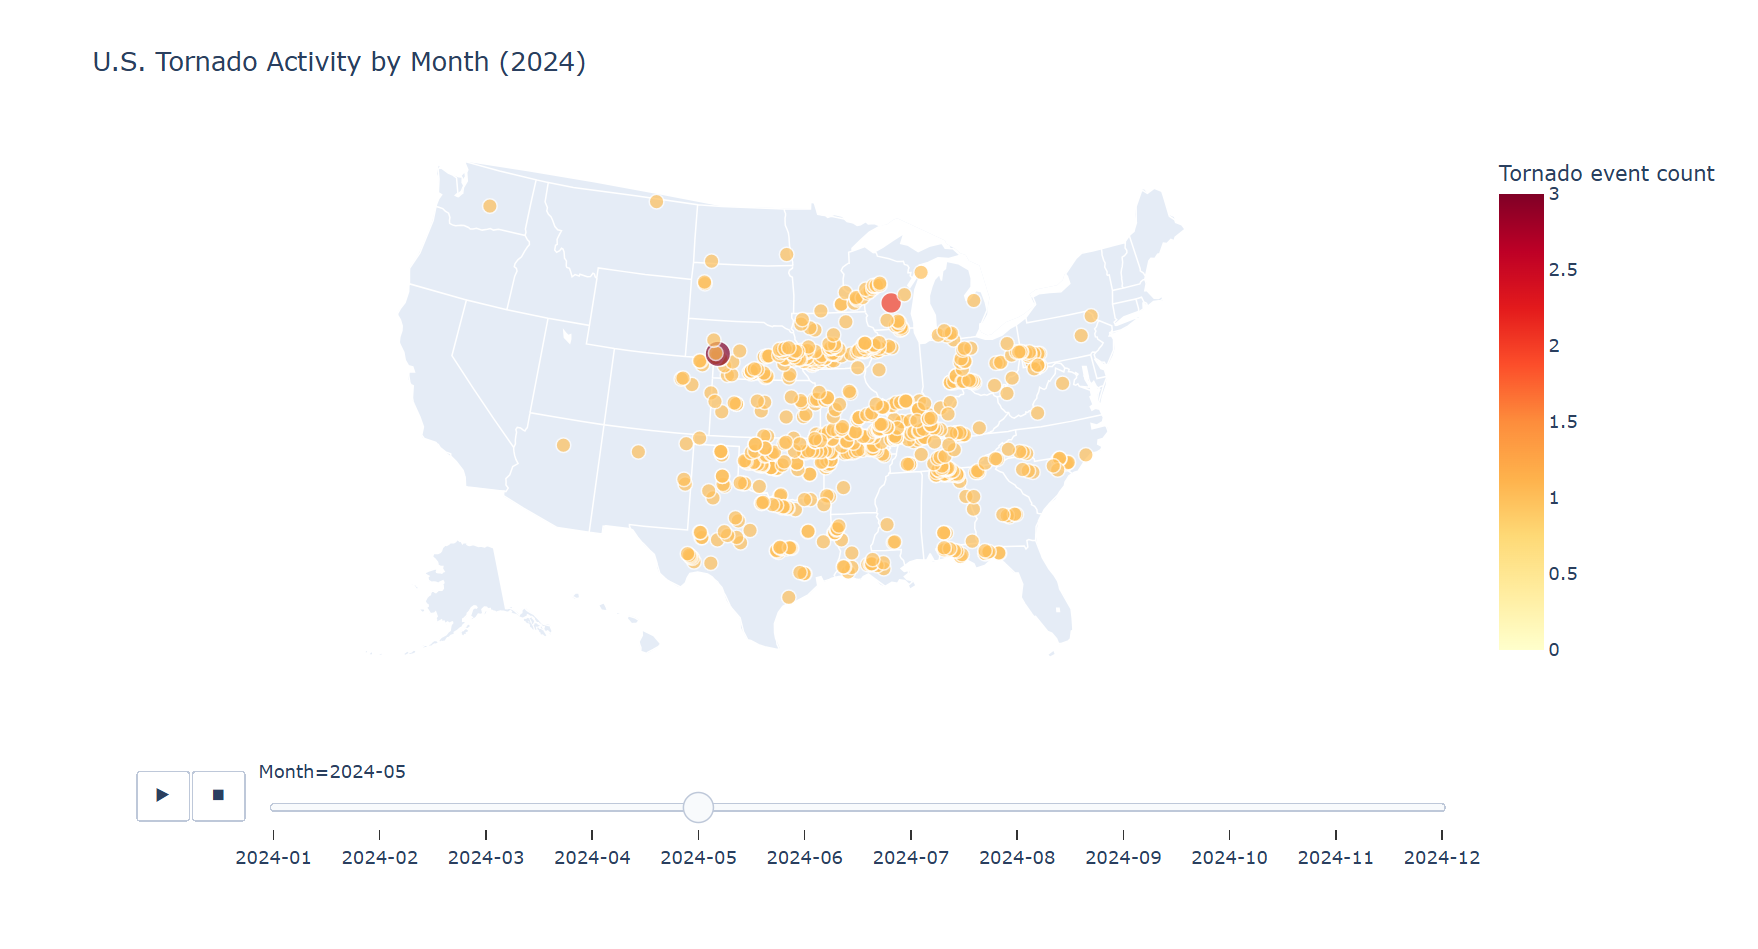

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer:

Figure 1 shows the geographic distribution of reported tornadoes across the United States during each month of 2024. In May 2024, tornado activity was concentrated across the central United States, particularly Oklahoma, Kansas, Missouri, Iowa, and surrounding states. The map shows individual tornado locations, with larger and darker markers representing more events at the same coordinates during that month. For example, the May 2024 map includes locations with up to 3 tornado events at a plotted location. The animation makes it possible to see how tornado activity changes geographically throughout the year.

In [27]:

import plotly.express as px

# Include zero-count state-month combinations
months = sorted(tornado_df["month"].unique())
states = sorted(tornado_df["STATE"].unique())

heatmap_data = (
    tornado_summary
    .pivot(index="STATE", columns="month", values="tornado_count")
    .reindex(index=states, columns=months)
    .fillna(0)
)

fig2 = px.imshow(
    heatmap_data,
    labels={
        "x": "Month",
        "y": "State",
        "color": "Tornado count"
    },
    color_continuous_scale="YlOrRd",
    aspect="auto",
    title="Reported Tornado Counts by State and Month (2024)"
)

fig2.update_layout(
    height=1100,
    width=1100
)

fig2.write_html(
    "tornado_figure2.html",
    include_plotlyjs=True,
    full_html=True,
    auto_open=True
)


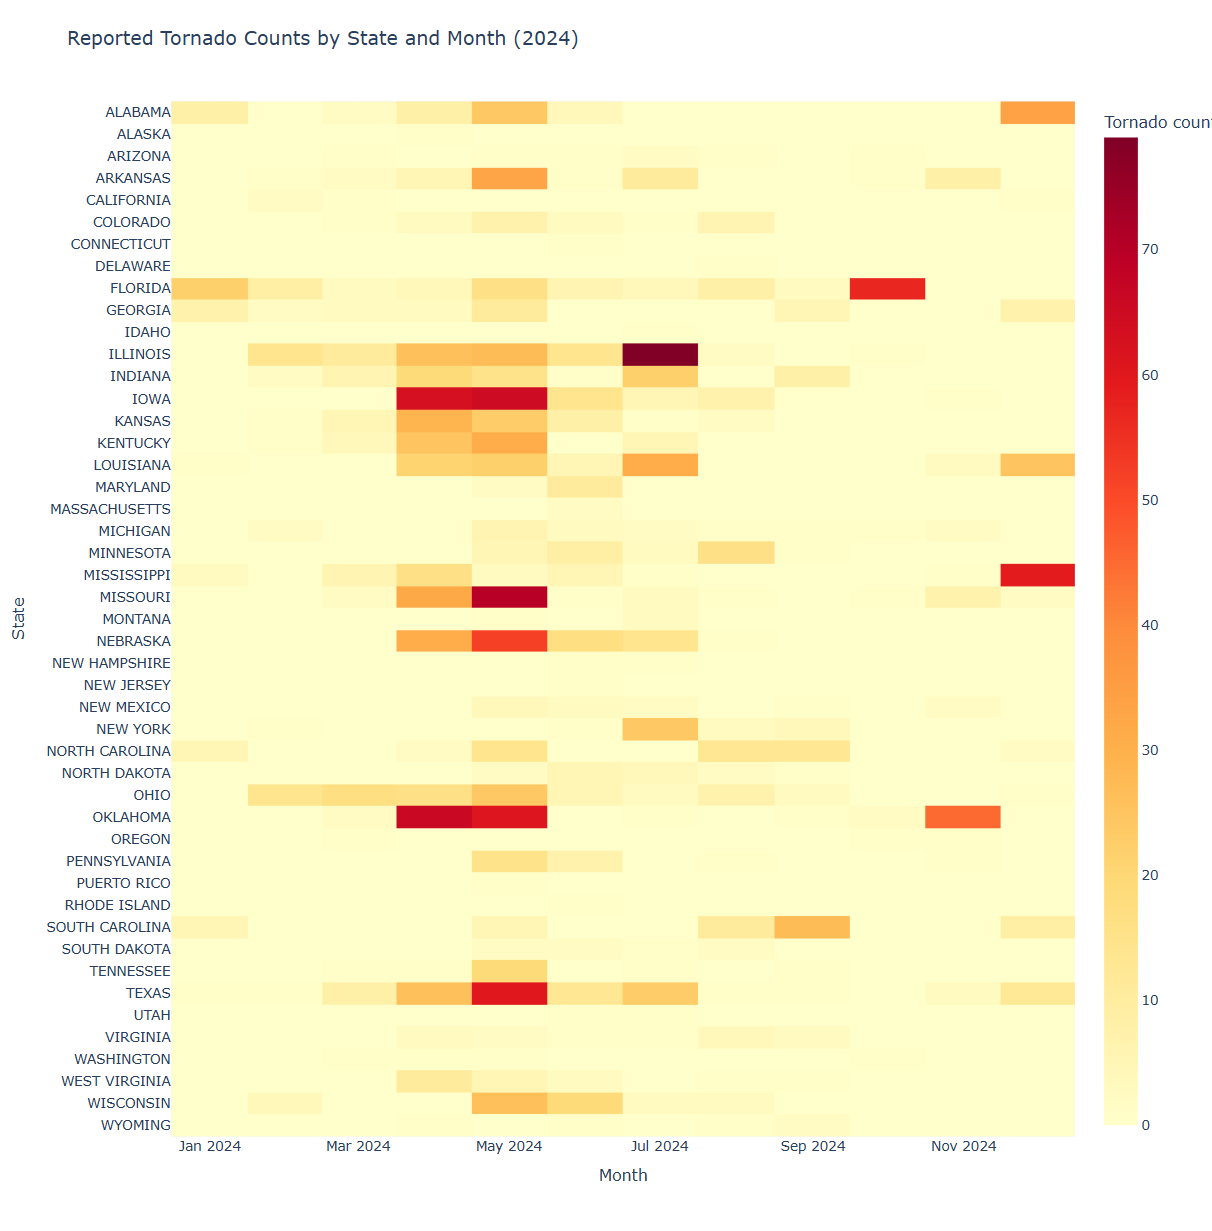

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer:

Figure 2 compares the number of reported tornadoes across states and months during 2024. The heatmap shows that tornado activity varied considerably by location and season. Illinois experienced particularly high activity in July 2024, with approximately 80 reported tornado events based on the color scale. Iowa, Oklahoma, Missouri, and Texas also experienced substantial activity during April and May. Compared with Figure 1, the heatmap makes it easier to compare monthly tornado counts between states, while the animated map provides more precise geographic locations. Both figures show that tornado activity was unevenly distributed across the United States throughout 2024.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [28]:

# Verify tornado counts shown in Figure 2
check_values = (
    tornado_df.groupby(["STATE", "BEGIN_YEARMONTH"])
    .size()
    .reset_index(name="Tornado_Count")
)

# Check Illinois in July and Iowa in April
selected_values = check_values[
    ((check_values["STATE"] == "ILLINOIS") &
     (check_values["BEGIN_YEARMONTH"] == 202407)) |
    ((check_values["STATE"] == "IOWA") &
     (check_values["BEGIN_YEARMONTH"] == 202404))
]

print("Values to compare with Figure 2:")
display(selected_values)

# Check chronological order
months = sorted(tornado_df["BEGIN_YEARMONTH"].unique())
print("\nMonths in chronological order:")
print(months)

# Check geographic coordinates
print("\nGeographic coordinate ranges:")
print("Latitude:", tornado_df["BEGIN_LAT"].min(),
      "to", tornado_df["BEGIN_LAT"].max())
print("Longitude:", tornado_df["BEGIN_LON"].min(),
      "to", tornado_df["BEGIN_LON"].max())

# Identify the highest state-month tornado count
print("\nHighest state-month tornado count:")
display(check_values.nlargest(1, "Tornado_Count"))


Values to compare with Figure 2:


,STATE,BEGIN_YEARMONTH,Tornado_Count
55,ILLINOIS,202407,79
65,IOWA,202404,63



Months in chronological order:
[np.int64(202401), np.int64(202402), np.int64(202403), np.int64(202404), np.int64(202405), np.int64(202406), np.int64(202407), np.int64(202408), np.int64(202409), np.int64(202410), np.int64(202411), np.int64(202412)]

Geographic coordinate ranges:
Latitude: 18.4721 to 61.13
Longitude: -149.66 to -66.7041

Highest state-month tornado count:


,STATE,BEGIN_YEARMONTH,Tornado_Count
55,ILLINOIS,202407,79


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer:

I checked two values from Figure 2 against the dataset summary. Illinois recorded 79 tornado events in July 2024, while Iowa recorded 63 tornado events in April 2024. Both values agreed with the patterns shown in the heatmap.

I also checked the chronological order and confirmed that the months were arranged from January through December 2024. The geographic coordinates ranged from 18.4721° to 61.13° latitude and -149.66° to -66.7041° longitude, consistent with the dataset's geographic coverage.

An unusual pattern was the high tornado activity in Illinois during July, which had the highest state-month count at 79 events. This confirmed that tornado activity varied considerably by both location and month. No corrections were needed based on these checks.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer:

My research question was: How did reported tornado activity vary across different U.S. states and months during 2024?

The results show that tornado activity varied significantly by both location and time. Figure 1, the animated geographic map, showed tornado events concentrated across the central and eastern United States, particularly during the spring and summer months.

Figure 2, the state-by-month heatmap, provided more specific comparisons. Illinois recorded 79 tornado events in July 2024, while Iowa recorded 63 tornado events in April 2024. These results demonstrate that different states experienced periods of high tornado activity at different times of the year.

The evidence supports my prediction that tornado activity would be more concentrated in certain regions and would increase during the warmer months. Both figures show that tornado activity was not evenly distributed geographically or throughout the year.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:

One limitation is that the dataset includes only reported tornado events. Tornadoes that were not observed or officially documented may be missing, which could affect the accuracy of comparisons between states.

A second limitation is that the analysis uses tornado counts rather than tornado intensity or damage. A state with more reported tornadoes did not necessarily experience more severe storms.

Figure 1 is useful for identifying the geographic distribution of tornadoes and observing how their locations change throughout the year. However, overlapping points can make it difficult to determine exact counts.

Figure 2 makes it easier to compare tornado counts between states and months. However, it does not show the precise locations of tornadoes within each state.

Using both figures provides a more complete understanding of tornado activity across the United States during 2024, although the analysis cannot fully explain why these patterns occurred.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes, I used ChatGPT as a learning resource during this project. Specifically, I asked ChatGPT to teach me how to add images and screenshots of my Plotly visualizations into my project. It provided step-by-step guidance on displaying and including the figures in my Jupyter Notebook. I used this assistance to better understand the process and complete the visual presentation of my work.

## Submission checklist

- Include two distinct datasets, each with both usable spatial and temporal information, plus any lookup or boundary files.
- Document both sources, feature definitions, units, collection context, coverage, and download filters.
- Complete the feature table and every written response for both investigations.
- Ask one research question per dataset and complete all six workflow steps for each question.
- Include four finished figures: two different chart types for each question, with each pair addressing both space and time.
- Explain filtering, missing values, aggregations, row counts, and any changes in the unit of observation.
- Check plotted values, temporal order, and geographic interpretation against the data.
- Restate each question in its conclusion and support the answer with evidence from both figures.
- Identify two limitations per investigation and compare what the two displays reveal or obscure.
- Complete the AI-use reflection. Restart the kernel, run cells in order, and ensure interactive figures display correctly before submitting.